In [2]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import recall_score, precision_score, f1_score, roc_auc_score

RANDOM_STATE = 42
DATA_PATH = Path("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
FIG_DIR = Path("../reports/figures")
MODEL_DIR = Path("../models")
sns.set_theme(style="whitegrid")

df = pd.read_csv(DATA_PATH)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
df = df.drop(columns=["customerID"])
df["Churn"] = (df["Churn"] == "Yes").astype(int)

X = df.drop(columns=["Churn"])
y = df["Churn"]
# Same random_state and stratify as notebook 02 -> identical test set
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

models = {"KNN": joblib.load(MODEL_DIR / "knn.joblib"),
          "Logistic Regression": joblib.load(MODEL_DIR / "logistic_regression.joblib"),
          "Random Forest": joblib.load(MODEL_DIR / "random_forest.joblib")}

In [3]:
def group_metrics(model, X_te, y_te, attr):
    y_pred = pd.Series(model.predict(X_te), index=X_te.index)
    rows = []
    for group in sorted(X_te[attr].unique()):
        mask = X_te[attr] == group
        yt, yp = y_te[mask], y_pred[mask]
        rows.append({"Attribute": attr, "Group": str(group), "n": int(mask.sum()),
                     "Actual churn rate": yt.mean(),
                     "Predicted churn rate": yp.mean(),
                     "Recall (TPR)": recall_score(yt, yp),
                     "False positive rate": ((yp == 1) & (yt == 0)).sum() / (yt == 0).sum(),
                     "Precision": precision_score(yt, yp)})
    return pd.DataFrame(rows)

tables = []
for name, m in models.items():
    for attr in ["gender", "SeniorCitizen"]:
        t = group_metrics(m, X_test, y_test, attr)
        t.insert(0, "Model", name)
        tables.append(t)

fairness_df = pd.concat(tables, ignore_index=True).round(3)
fairness_df.to_csv("../reports/fairness_by_group.csv", index=False)
fairness_df

,Model,Attribute,Group,n,Actual churn rate,Predicted churn rate,Recall (TPR),False positive rate,Precision
0,KNN,gender,Female,687,0.281,0.447,0.793,0.312,0.498
1,KNN,gender,Male,722,0.251,0.452,0.807,0.333,0.448
2,KNN,SeniorCitizen,0,1187,0.233,0.407,0.768,0.297,0.439
3,KNN,SeniorCitizen,1,222,0.441,0.676,0.888,0.508,0.580
4,Logistic Regression,gender,Female,687,0.281,0.408,0.772,0.265,0.532
5,Logistic Regression,gender,Male,722,0.251,0.421,0.801,0.294,0.477
6,Logistic Regression,SeniorCitizen,0,1187,0.233,0.365,0.736,0.252,0.469
7,Logistic Regression,SeniorCitizen,1,222,0.441,0.680,0.929,0.484,0.603
8,Random Forest,gender,Female,687,0.281,0.351,0.699,0.215,0.560
9,Random Forest,gender,Male,722,0.251,0.363,0.746,0.235,0.515


In [4]:
# Recall gap / FPR gap: difference between groups (0 = perfectly equal)
# Disparate impact: lower predicted-churn rate / higher one (1 = equal; < 0.8 is a common warning sign)
gaps = (fairness_df.groupby(["Model", "Attribute"])
        .agg(recall_gap=("Recall (TPR)", lambda s: s.max() - s.min()),
             fpr_gap=("False positive rate", lambda s: s.max() - s.min()),
             disparate_impact=("Predicted churn rate", lambda s: s.min() / s.max()))
        .round(3))
gaps

recall_gap  fpr_gap  disparate_impact
Model               Attribute                                           
KNN                 SeniorCitizen       0.120    0.211             0.602
                    gender              0.014    0.021             0.989
Logistic Regression SeniorCitizen       0.193    0.232             0.537
                    gender              0.029    0.029             0.969
Random Forest       SeniorCitizen       0.114    0.229             0.526
                    gender              0.047    0.020             0.967

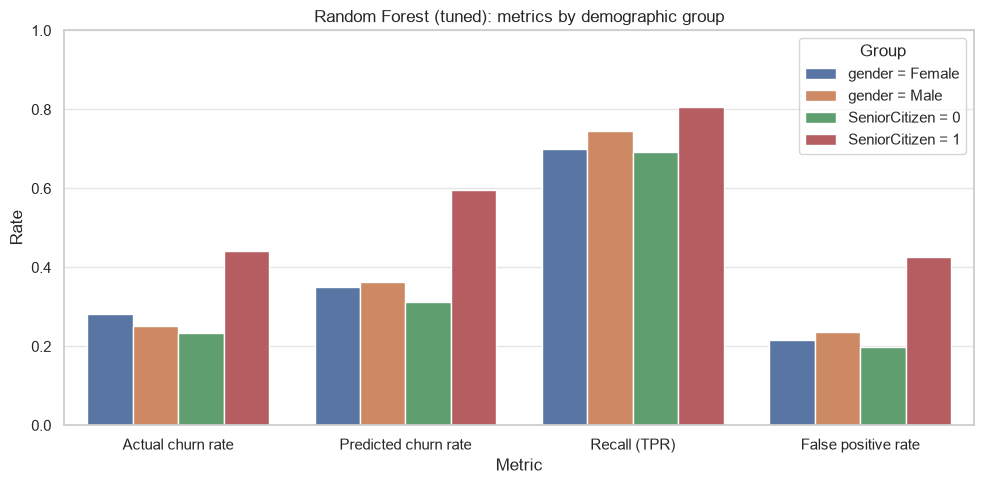

In [5]:
rf_df = fairness_df[fairness_df["Model"] == "Random Forest"].copy()
rf_df["Group"] = rf_df["Attribute"] + " = " + rf_df["Group"]
plot_df = rf_df.melt(id_vars=["Group"],
                     value_vars=["Actual churn rate", "Predicted churn rate",
                                 "Recall (TPR)", "False positive rate"],
                     var_name="Metric", value_name="Rate")

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=plot_df, x="Metric", y="Rate", hue="Group", ax=ax)
ax.set_ylim(0, 1)
ax.set_title("Random Forest (tuned): metrics by demographic group")
plt.tight_layout()
plt.savefig(FIG_DIR / "10_fairness_by_group.png", dpi=150)
plt.show()

In [7]:
# Retrain each tuned model WITHOUT gender, SeniorCitizen, Partner, Dependents
demographics = ["gender", "SeniorCitizen", "Partner", "Dependents"]
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols_nodemo = [c for c in X.columns if c not in num_cols + demographics]
X_train_nd = X_train.drop(columns=demographics)
X_test_nd = X_test.drop(columns=demographics)

rows = []
for name, m in models.items():
    m_nd = clone(m)   # same tuned hyperparameters, untrained
    m_nd.set_params(prep__transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat_cols_nodemo)])
    m_nd.fit(X_train_nd, y_train)
    rows.append({"Model": name,
                 "F1 (all features)": f1_score(y_test, m.predict(X_test)),
                 "F1 (no demographics)": f1_score(y_test, m_nd.predict(X_test_nd)),
                 "ROC-AUC (all features)": roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]),
                 "ROC-AUC (no demographics)": roc_auc_score(y_test, m_nd.predict_proba(X_test_nd)[:, 1])})

ablation_df = pd.DataFrame(rows).round(3)
ablation_df.to_csv("../reports/demographic_ablation.csv", index=False)
ablation_df

,Model,F1 (all features),F1 (no demographics),ROC-AUC (all features),ROC-AUC (no demographics)
0,KNN,0.594,0.595,0.822,0.822
1,Logistic Regression,0.614,0.619,0.839,0.840
2,Random Forest,0.616,0.624,0.838,0.841
